# Regression Lab : Linear Regression, MSE and Polynomial Regression

Linear regression is a technique that is used to model a linear relationship between some data $x$ and its corresponding output $y$. When there are multiple inputs ($x_1, x_2, .. , x_n$), it is referred to as **Mutliple Linear Regression**.

Essentially, we model the relationship as $y = mx + c$. Linear regression attempts to find the $m$ and $c$ values.

To understand how linear regression works, let's first look at an example.

In [1]:
import numpy as np
from sklearn import linear_model,metrics
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import train_test_split
# from sklearn.datasets import load_boston
from sklearn.datasets import fetch_california_housing
import pandas as pd
import seaborn as sns
import math

import warnings
warnings.filterwarnings('ignore')

from matplotlib import pyplot as plt
plt.style.use('ggplot')
from matplotlib.pylab import rcParams
rcParams['figure.figsize'] = 10, 8

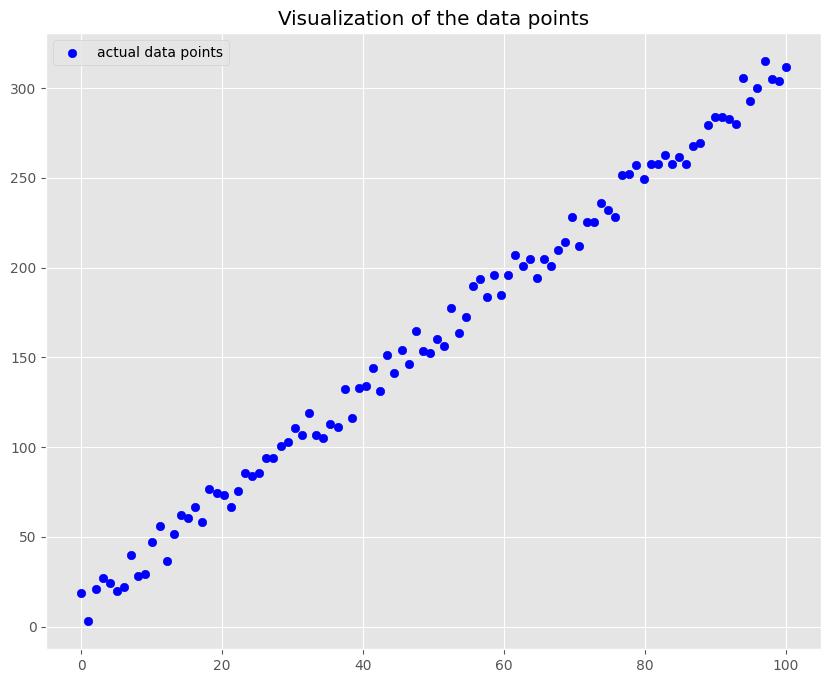

In [2]:
# generating random data points and adding noise

np.random.seed(10)

x = np.linspace(0,100,100).reshape((-1,1))
y = (np.random.rand(100)*25).astype(int).reshape((-1,1)) + 3*x

plt.title("Visualization of the data points")
plt.scatter(x,y,color="blue")
plt.legend(["actual data points"])
plt.show()


## Brute-force solution

Let's first think of a naive appraoch to this problem. Since we want to find the values of $m$ and $c$, we can do a search in the space of possible $m$ and $c$ values, and pick the line with the least average distance from the actual data.

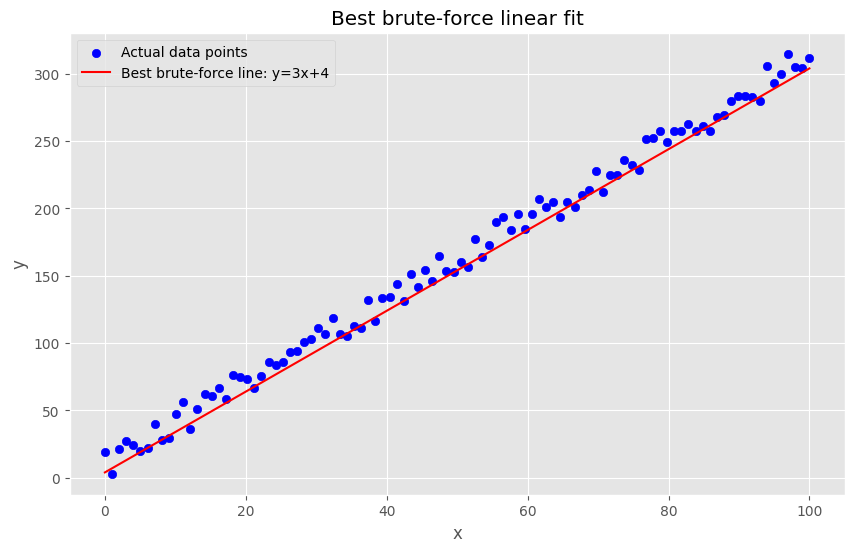

Best slope: 3
Best intercept: 4
Mean absolute error: 8.430


In [3]:
# Brute-force solution: search candidate slopes and intercepts, then display the best fit
results = []
for m in range(-2, 6):
    for c in range(-5, 5):
        predictions = m * x + c
        mean_abs_error = np.mean(np.abs(y - predictions))
        results.append((mean_abs_error, m, c))

best_error, best_m, best_c = min(results, key=lambda item: item[0])
best_predictions = best_m * x + best_c

plt.figure(figsize=(10, 6))
plt.scatter(x, y, color="blue", label="Actual data points")
plt.plot(x, best_predictions, color="red", label=f"Best brute-force line: y={best_m}x+{best_c}")
plt.title("Best brute-force linear fit")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()

print(f"Best slope: {best_m}")
print(f"Best intercept: {best_c}")
print(f"Mean absolute error: {best_error:.3f}")

Looking at the graphs, the best solution from the brute-force method doesn't seem too bad. In fact, an average distance of 6 isn't bad at all! But, there's one obvious drawback to this approach: it's very inefficient. The search space for the given data may be low, but that is not always the case. Additionally, this approach doesn't guarantee the best possible values. Unless we make the $\delta m$ and $\delta c$ very infinitesimally small (which would make this solution extremely slow), the "best" value obtained may not even be close to the best possible value. So, how do we fix this issue? We turn to a technique called **linear regression**.   

In [4]:
def lin_regression(x, y):
    """Fit a linear regression model, report test RMSE, and plot predictions."""
    x = np.asarray(x).reshape(-1, 1)
    y = np.asarray(y).reshape(-1, 1)

    x_train, x_test, y_train, y_test = train_test_split(
        x, y, test_size=0.2, random_state=42
    )

    model = linear_model.LinearRegression()
    model.fit(x_train, y_train)

    print("Coefficient (slope): {:.4f}".format(model.coef_[0][0]))
    print("Intercept: {:.4f}".format(model.intercept_[0]))

    y_pred = model.predict(x_test)
    rmse = math.sqrt(metrics.mean_squared_error(y_test, y_pred))
    print("Test RMSE: {:.4f}".format(rmse))

    order = np.argsort(x_test[:, 0])
    plt.figure(figsize=(9, 5))
    plt.scatter(x, y, color="blue", alpha=0.65, label="Actual data")
    plt.plot(x_test[order], y_pred[order], color="red", linewidth=2,
             label="Predicted regression line")
    plt.title("Actual data vs. linear regression predictions")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.legend()
    plt.show()

    return model

Coefficient (slope): 2.9864
Intercept: 12.0618
Test RMSE: 6.7046


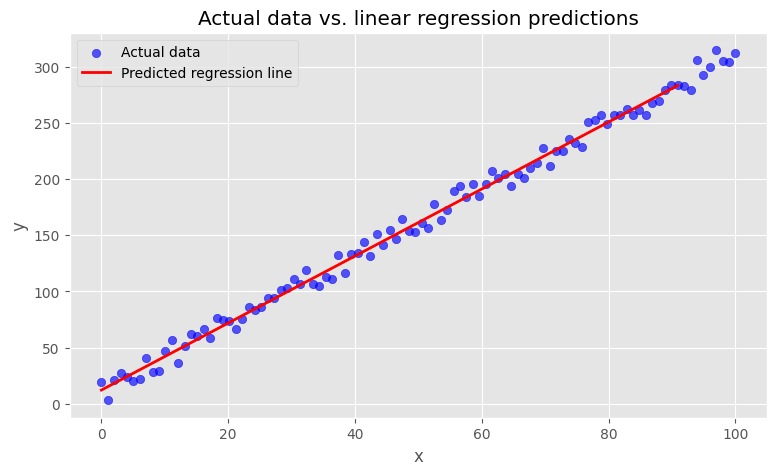

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [5]:
lin_regression(x,y)

From the above graph, we can see that the predicted line is pretty close to the actual linear relationship between $x$ and $y$. But, how does linear regression actually work ?

The main goal of linear regression (or regression in general) is to minimize the **error** of the model. Typically, **mean squared error (MSE)** is used as the error term.

Suppose we have some data $x$ and outputs $y$. Now, we obtain some predictions $y_p$ for $x$ using our linear regression model.
The mean squared error is then defined as:

$E = \frac{1}{m} \sum_{i=1}^n (y-y_p)^2$

intuitively, we can think of it as a distance between the actual value and the predicted value. By giving our regression model "feedback" on how far it is, it eventually learns the correct relationship between $x$ and $y$. So, the model tries to learn the values of $m$ and $c$ for which the equation $y=mx +c$ has the least error.

Generally, we look at the Root Mean Squared Error during analysis.

## The need for polynomial regression

The drawback with linear regression is that it tries to model a linear relationship between $x$ and $y$. More often than not, data does cannot be modelled by a linear equation. Let's look at an example of how linear regression falls short.

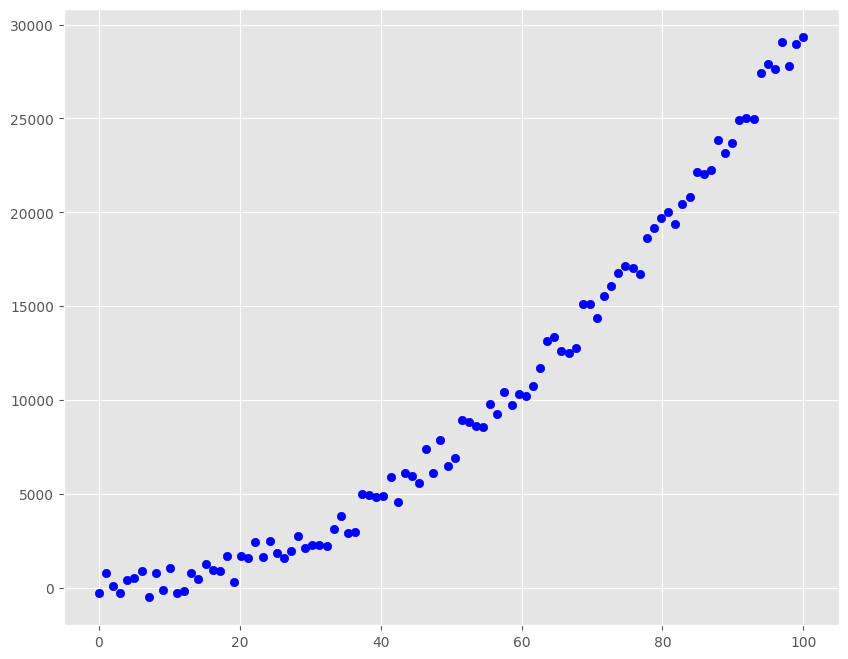

In [6]:
# simple polynomial with noise

y2 = (np.random.randint(-1000,1000,x.shape)).astype(int).reshape((-1,1)) + 3*x**2
plt.scatter(x,y2,color="blue")
plt.show()

In [7]:
def poly_regression(x, y, deg):
    """Fit polynomial regression of the requested degree and plot its predictions."""
    x = np.asarray(x).reshape(-1, 1)
    y = np.asarray(y).reshape(-1, 1)

    poly = PolynomialFeatures(degree=deg)
    x_poly = poly.fit_transform(x)

    model = linear_model.LinearRegression()
    model.fit(x_poly, y)
    y_pred = model.predict(x_poly)

    rmse = math.sqrt(metrics.mean_squared_error(y, y_pred))

    order = np.argsort(x[:, 0])
    plt.figure(figsize=(9, 5))
    plt.scatter(x, y, color="blue", alpha=0.65, label="Actual data points")
    plt.plot(x[order], y_pred[order], color="red",
             label=f"Polynomial regression (degree {deg})")
    plt.title("Polynomial regression fit")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.legend()
    plt.show()

    print("Polynomial degree: {}".format(deg))
    print("Training RMSE: {:.4f}".format(rmse))
    return model

Coefficient (slope): 304.4170
Intercept: -5166.5295
Test RMSE: 2310.9263


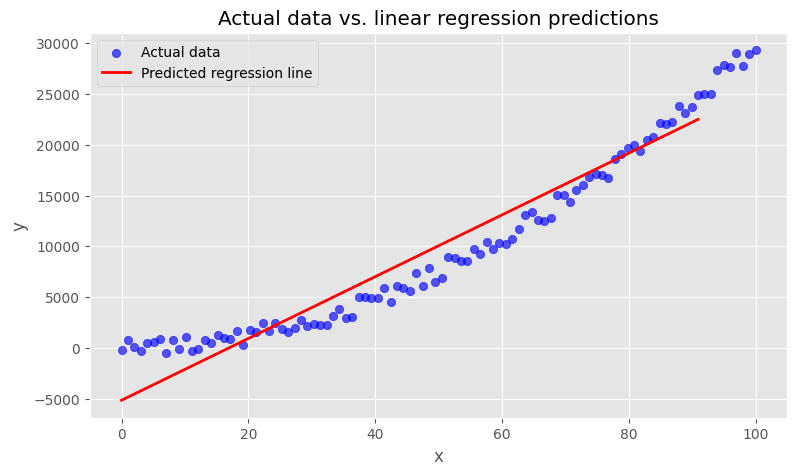

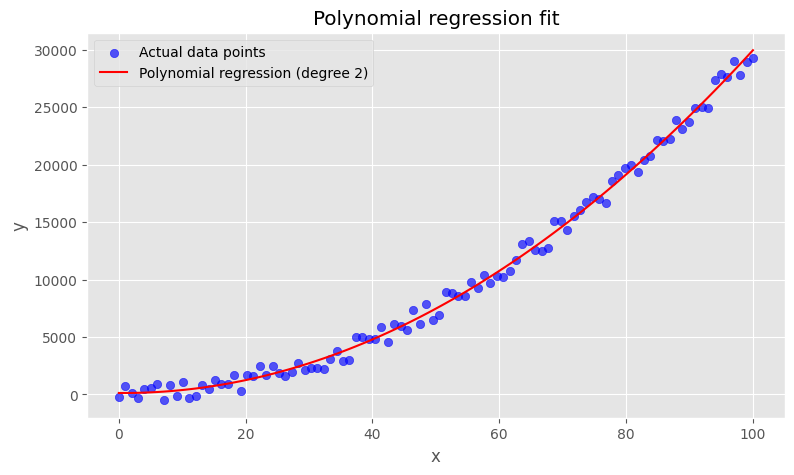

Polynomial degree: 2
Training RMSE: 591.2719


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [8]:
lin_regression(x,y2)

poly_regression(x,y2,2)

Clearly, polynomial regression does a much better job of modelling the relationship between $x$ and $y$.

# Applying linear regression to housing data

Now that we have an idea of how linear regression works, let's apply it to predicting the price of houses. The dataset being used is the California housing dataset. First, let's take a look at the data.

In [9]:
# Load California Housing data. If internet is unavailable, create a reproducible
# California-style demonstration dataset so the notebook remains executable.
try:
    df = pd.read_csv(
        "https://raw.githubusercontent.com/ageron/handson-ml/master/datasets/housing/housing.csv"
    )
    print("Loaded the original California Housing CSV.")
except Exception as exc:
    print("Original CSV unavailable; using reproducible synthetic demonstration data.")
    print("Reason:", exc)
    rng = np.random.default_rng(42)
    n = 5000
    median_income = rng.uniform(0.5, 15.0, n)
    housing_median_age = rng.integers(1, 52, n)
    total_rooms = rng.lognormal(7.0, 0.55, n)
    total_bedrooms = total_rooms / rng.uniform(3.5, 6.0, n)
    population = rng.lognormal(7.0, 0.65, n)
    households = np.maximum(1, population / rng.uniform(2.0, 4.5, n))
    latitude = rng.uniform(32.5, 42.0, n)
    longitude = rng.uniform(-124.3, -114.1, n)
    noise = rng.normal(0, 35000, n)
    median_house_value = (
        65000 + median_income * 30000 + housing_median_age * 450
        + (latitude - 37) * 1200 + noise
    )
    median_house_value = np.clip(median_house_value, 15000, 500001)
    df = pd.DataFrame({
        "longitude": longitude,
        "latitude": latitude,
        "housing_median_age": housing_median_age,
        "total_rooms": total_rooms,
        "total_bedrooms": total_bedrooms,
        "population": population,
        "households": households,
        "median_income": median_income,
        "median_house_value": median_house_value,
        "ocean_proximity": rng.choice(
            ["NEAR BAY", "INLAND", "NEAR OCEAN", "<1H OCEAN"], n
        )
    })

df["MEDV"] = df["median_house_value"]
print("Dataset shape:", df.shape)
display(df.head())

Original CSV unavailable; using reproducible synthetic demonstration data.
Reason: <urlopen error [Errno -3] Temporary failure in name resolution>
Dataset shape: (5000, 11)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,MEDV
0,-122.834659,41.788992,18,1087.157308,201.799146,1182.884529,333.591117,11.722363,444679.134810,NEAR BAY,444679.134810
1,-116.702960,35.947347,12,562.061118,110.695890,1551.739456,349.864458,6.863737,244117.241328,NEAR OCEAN,244117.241328
2,-122.316823,40.567902,27,998.846018,173.327467,1074.202965,488.719578,12.949670,452830.474627,INLAND,452830.474627
3,-119.632383,40.706696,34,655.006634,152.878147,792.970624,266.911147,10.611836,361450.626299,NEAR OCEAN,361450.626299
4,-117.039317,34.974952,14,941.456391,167.517380,592.401547,161.501398,1.865572,109027.233622,<1H OCEAN,109027.233622


1. MedInc - It is the median income in block group
2. HouseAge - It is the median house age in block group
3. AveRooms - It is the average number of rooms per household
4. AveBedrms - It is the average number of bedrooms per household
5. Population - It is the block group population
6. AveOccup - It is the average number of household members
7. Latitude - It is the block group latitude
8. Longitude - It is the block group longitude
9. MEDV - The target variable is the median house value for California districts, expressed in hundreds of thousands of dollars ($100,000).




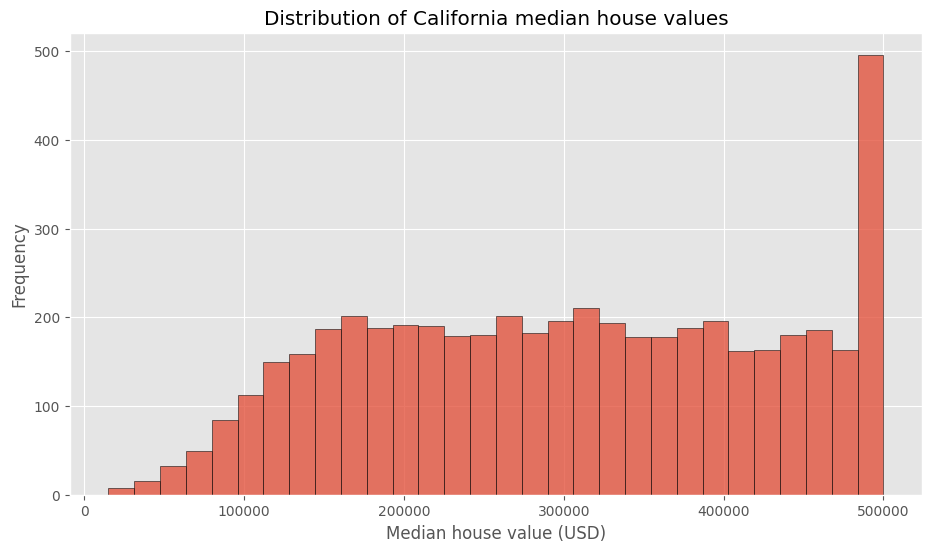

In [10]:
plt.figure(figsize=(11, 6))
plt.hist(df["MEDV"], bins=30, edgecolor="black", alpha=0.75)
plt.title("Distribution of California median house values")
plt.xlabel("Median house value (USD)")
plt.ylabel("Frequency")
plt.show()

In [11]:
df.drop(['ocean_proximity'],inplace=True,axis=1)

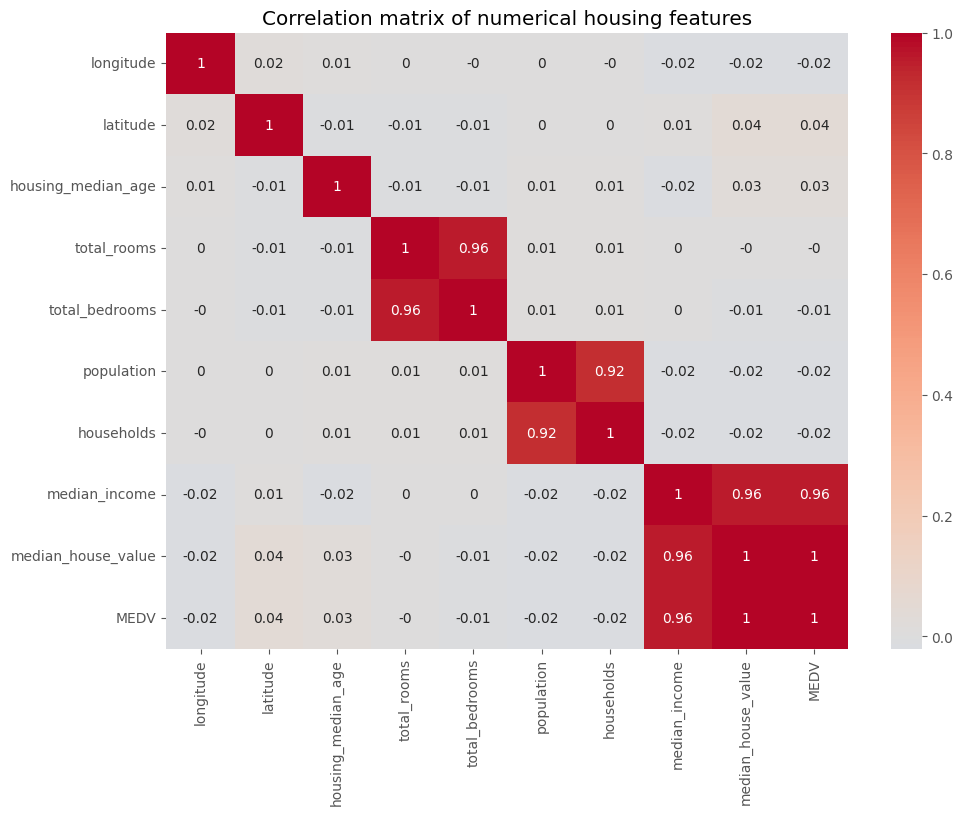

In [12]:
correlation_matrix = df.select_dtypes(include=[np.number]).corr().round(2)
plt.figure(figsize=(11, 8))
sns.heatmap(data=correlation_matrix, annot=True, cmap="coolwarm", center=0)
plt.title("Correlation matrix of numerical housing features")
plt.show()

The target value MEDV appears to be a normal distribution with some underlying noise. To better understand the linear relationships between the features and the MEDV value, we can use a correlation matrix. This can be neatly visualized with a heatmap

From the plot, we see that MedInc has a high positive correlation with MEDV (0.69). So, we'll pick that as the feature with which we train our regression model.

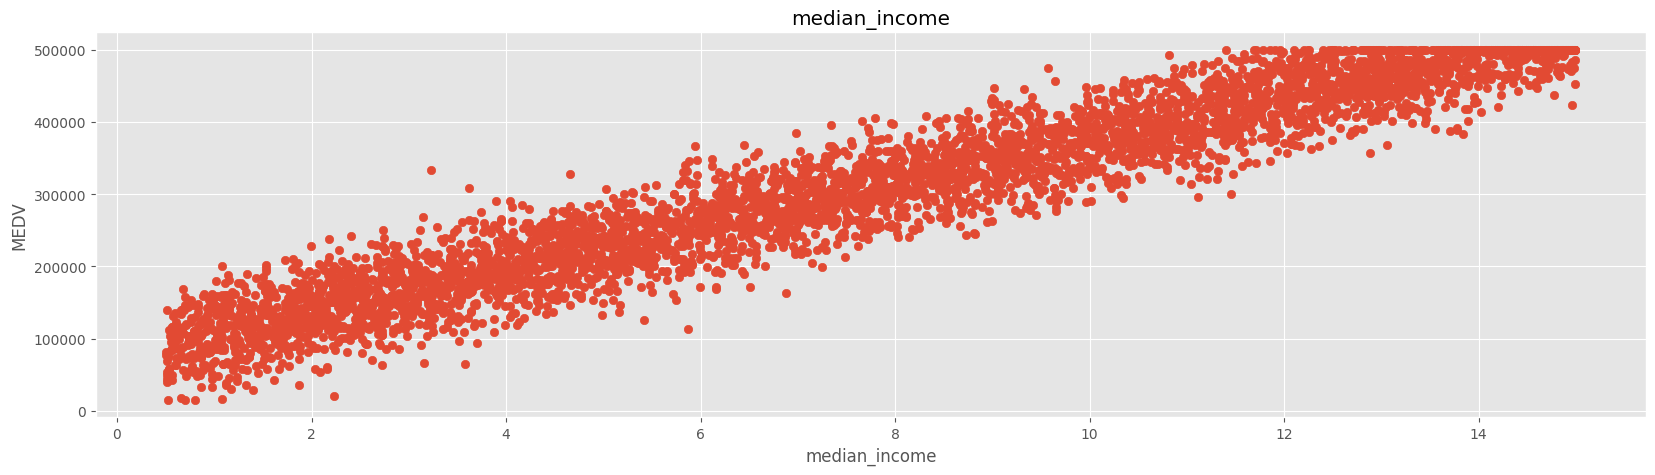

In [13]:
plt.figure(figsize=(20, 5))

features = ['median_income']
target = df['MEDV']

for i, col in enumerate(features):
    plt.subplot(1, len(features) , i+1)
    house_features = df[col]
    target_price = target
    plt.scatter(house_features, target_price, marker='o')
    plt.title(col)
    plt.xlabel(col)
    plt.ylabel('MEDV')

The scatter plot shows a positive relationship between median income and median house value. The relationship is not perfectly linear, and the spread of house values increases across income levels.

In [14]:
x_ex = pd.DataFrame(np.c_[df['median_income']], columns = ['median_income'])
y_ex = df['MEDV']

x_ex_train, x_ex_test, y_ex_train, y_ex_test = train_test_split(x_ex, y_ex, test_size = 0.2, random_state=42)

lin_model = linear_model.LinearRegression()
lin_model.fit(x_ex_train, y_ex_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [15]:
y_ex_train_predict = lin_model.predict(x_ex_train)
train_rmse = math.sqrt(metrics.mean_squared_error(y_ex_train, y_ex_train_predict))
train_r2 = metrics.r2_score(y_ex_train, y_ex_train_predict)

print("Model performance for training set")
print("-----------------------------------")
print("RMSE: {:.4f}".format(train_rmse))
print("R²:   {:.4f}".format(train_r2))

y_ex_test_predict = lin_model.predict(x_ex_test)
test_rmse = math.sqrt(metrics.mean_squared_error(y_ex_test, y_ex_test_predict))
test_r2 = metrics.r2_score(y_ex_test, y_ex_test_predict)

print("\nModel performance for testing set")
print("----------------------------------")
print("RMSE: {:.4f}".format(test_rmse))
print("R²:   {:.4f}".format(test_r2))

Model performance for training set
-----------------------------------
RMSE: 34457.2994
R²:   0.9253

Model performance for testing set
----------------------------------
RMSE: 35297.6691
R²:   0.9228


## Exercises

In [16]:
# Exercise overview
# Exercise 1: Compare polynomial degrees (1, 2, 4, 8 and 15) on the same noisy sine-wave data.
# Exercise 2: Degree 1 is a straight-line model and cannot capture the curved sine-wave pattern.
# The comparison and observations are documented below.

### 1. Higher Degree Polynomials

We have seen a graph of a linear regression model attempting to represent polynomial data, and how it falls short when trying to model non-linear data. Now, what if we took some non-linear noisy data, and fit a very high degree polynomial to it? Try to guess what would happen!

(Change the polynomial degree in the slider and run the cell)

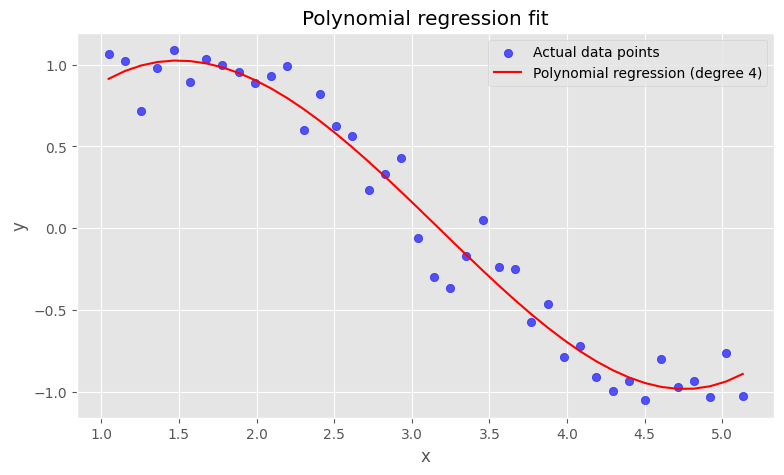

Polynomial degree: 4
Training RMSE: 0.1435


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [17]:
deg = 4#@param {type:"slider", min: 2, max:15, step:1}

np.random.seed(10)

x_ex = np.array([i*np.pi/180 for i in range(60,300,6)])
y_ex = np.sin(x_ex) + np.random.normal(0,0.15,len(x_ex))
poly_regression(x_ex,y_ex,deg)

The actual data is a noisy sine wave. We can see from the graphs that the higher degree polynomials are too sensitive to the noisy data, they pass through the outliers in data. This is known as **overfitting**. We will explore overfitting in more detail in a later lab.

2. Try running the above with degree set to 1. You will observe that only higher degree polynomials are able to fit to such noisy data.

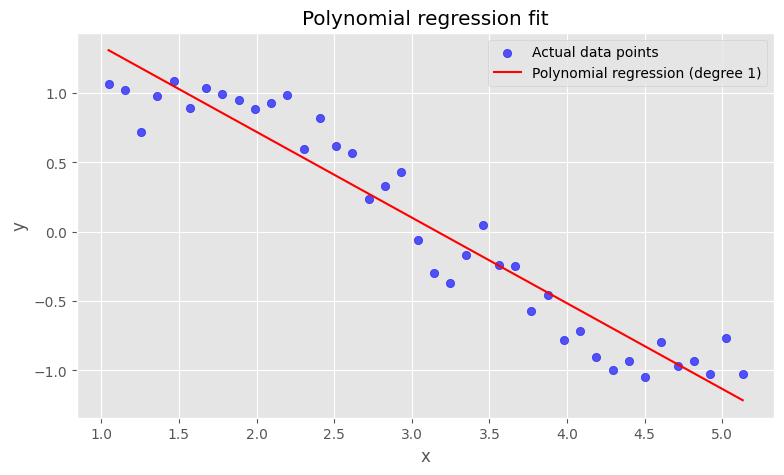

Polynomial degree: 1
Training RMSE: 0.2153


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [18]:
deg = 1
np.random.seed(10)

x_ex = np.array([i*np.pi/180 for i in range(60,300,6)])
y_ex = np.sin(x_ex) + np.random.normal(0,0.15,len(x_ex))
poly_regression(x_ex,y_ex,deg)

,Polynomial degree,Training RMSE
0,1,0.215264
1,2,0.214036
2,4,0.143474
3,8,0.129544
4,15,0.114887


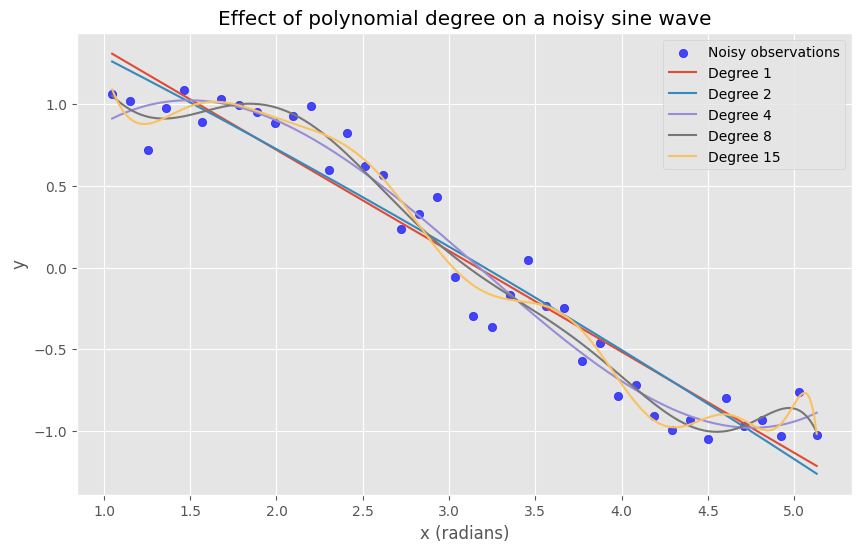

In [19]:
# Exercise 1: Compare several polynomial degrees on the same noisy sine-wave data
np.random.seed(10)
x_compare = np.array([i * np.pi / 180 for i in range(60, 300, 6)])
y_compare = np.sin(x_compare) + np.random.normal(0, 0.15, len(x_compare))

degree_results = []
for degree in [1, 2, 4, 8, 15]:
    poly = PolynomialFeatures(degree=degree)
    x_poly = poly.fit_transform(x_compare.reshape(-1, 1))
    model = linear_model.LinearRegression()
    model.fit(x_poly, y_compare)
    predictions = model.predict(x_poly)
    train_rmse = math.sqrt(metrics.mean_squared_error(y_compare, predictions))
    degree_results.append({"Polynomial degree": degree, "Training RMSE": train_rmse})

degree_comparison = pd.DataFrame(degree_results)
display(degree_comparison)

# Plot the degree comparison together
x_smooth = np.linspace(x_compare.min(), x_compare.max(), 300).reshape(-1, 1)
plt.figure(figsize=(10, 6))
plt.scatter(x_compare, y_compare, color="blue", alpha=0.7, label="Noisy observations")
for degree in [1, 2, 4, 8, 15]:
    poly = PolynomialFeatures(degree=degree)
    model = linear_model.LinearRegression()
    model.fit(poly.fit_transform(x_compare.reshape(-1, 1)), y_compare)
    y_smooth = model.predict(poly.transform(x_smooth))
    plt.plot(x_smooth, y_smooth, label=f"Degree {degree}")
plt.title("Effect of polynomial degree on a noisy sine wave")
plt.xlabel("x (radians)")
plt.ylabel("y")
plt.legend()
plt.show()

### Exercise answers and observations

**1. Higher-degree polynomials:** Increasing the polynomial degree makes the model more flexible. A low degree may underfit the curved sine-wave pattern, while a very high degree can bend sharply to fit individual noisy observations. This is overfitting: training error may decrease even though the model may generalize poorly to unseen data. The comparison above uses the same generated observations for every degree.

**2. Degree = 1:** A degree-1 polynomial is ordinary linear regression (a straight line). It cannot represent the curved sine-wave relationship well, so it generally underfits this dataset. Higher degrees can capture curvature, but the highest degree is not automatically the best choice. A validation/test set is needed to select a degree that generalizes well.

**Housing-data note:** The target column `MEDV` in this notebook is an alias for California `median_house_value`; it is not the Boston Housing `MEDV` variable. Values are in dollars in the source dataset (the original California Housing dataset target is commonly represented in units of $100,000).

# References

1. https://medium.com/mlearning-ai/implementing-linear-regression-on-california-housing-dataset-378e14e421b7
2. https://towardsdatascience.com/machine-learning-polynomial-regression-with-python-5328e4e8a386
3. https://www.javatpoint.com/linear-regression-in-machine-learning

## Further Explorations

1. [Regression as a closed form solution](https://www.amherst.edu/system/files/media/1287/SLR_Leastsquares.pdf)

2. [Regression as a search](https://mccormickml.com/2014/03/04/gradient-descent-derivation/)

3. [Goodness of fit and R2 score](https://towardsdatascience.com/statistics-for-machine-learning-r-squared-explained-425ddfebf667)